

# Case-Study Activity: The I-94 "Traffic Pulse"
**UE24CS342AA9 · Unit 3 · PPT 5: Animation, Motion and Temporal Visualization · Duration: ~28 minutes**

**Dataset:** Metro Interstate Traffic Volume (Kaggle) — https://www.kaggle.com/datasets/anshtanwar/metro-interstate-traffic-volume
Hourly westbound traffic on Interstate 94 between Minneapolis and St Paul (2012–2018), with weather and holidays.

---
### 📋 The case
You have just joined the **Minnesota Department of Transportation (MnDOT)** as a data-visualization analyst. Your manager needs two things:

1. **For the road-works engineers:** evidence for *when* a daytime lane closure on I-94 would disrupt the fewest drivers.
2. **For the public lobby screen:** an animated *"Traffic Pulse"* that shows how a typical day's traffic changes through the year.

A vendor has also offered to cut storage costs by **recording traffic only once every 25 hours**. You need to advise on that too.

Each part has **💻 coding tasks** (checked automatically) and **✍️ reflection questions** (write 2–3 sentences each).

Name : Vaishnavi Goyal

SRN : PES2UG24CS571

## Part 0 — Setup (1 min): run both cells, don't edit

In [1]:
%pip install -q kagglehub plotly

In [2]:
import os, glob, calendar, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, plotly.express as px
warnings.filterwarnings("ignore")

if os.path.exists("Metro_Interstate_Traffic_Volume.csv"):
    path = "Metro_Interstate_Traffic_Volume.csv"
else:
    import kagglehub
    path = sorted(glob.glob(os.path.join(kagglehub.dataset_download("anshtanwar/metro-interstate-traffic-volume"), "**", "*.csv"), recursive=True))[0]

raw = pd.read_csv(path); raw.columns = raw.columns.str.strip().str.lower()
for kw in [dict(format="%Y-%m-%d %H:%M:%S"), dict(format="%d-%m-%Y %H:%M"), dict(format="%d-%m-%Y %H:%M:%S"), dict(format="mixed", dayfirst=True)]:
    t = pd.to_datetime(raw["date_time"], errors="coerce", **kw)
    if t.notna().mean() > 0.99: raw["date_time"] = t; break
raw["holiday"] = raw["holiday"].fillna("None").astype(str).str.strip().replace({"": "None", "nan": "None"})
print(f"raw: {len(raw):,} rows, {raw.date_time.min()} → {raw.date_time.max()}")
raw.head()

Using Colab cache for faster access to the 'metro-interstate-traffic-volume' dataset.
raw: 48,204 rows, 2012-10-02 09:00:00 → 2018-09-30 23:00:00


,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00
1,4516,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00
2,4767,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00
3,5026,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00
4,4918,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00


In [3]:
# ===================== AUTO-CHECKER — run, do not edit =====================
_S = {}
def _r(k, ok, good, hint):
    _S[k] = bool(ok); print(("✅ " + good) if ok else ("❌ Not yet — hint: " + hint))
def _exp_clean():
    t = raw.drop_duplicates("date_time").sort_values("date_time").set_index("date_time")
    h = t.loc[t.holiday != "None", "holiday"]; hd = pd.Series(h.values, index=h.index.normalize()); hd = hd[~hd.index.duplicated()]
    t["holiday_day"] = t.index.normalize().map(hd).fillna("None"); return t
_T = _exp_clean()

def check_A(n_dups, tr, modal_interval_h, longest_gap_days):
    g = _T.index.to_series().diff().dropna()
    if n_dups != raw.date_time.duplicated().sum(): return _r("A", 0, "", "count duplicated timestamps in raw['date_time'] with .duplicated().sum().")
    if not (isinstance(tr, pd.DataFrame) and len(tr) == len(_T) and tr.index.is_monotonic_increasing):
        return _r("A", 0, "", "drop duplicate timestamps, sort, and set 'date_time' as the index.")
    if abs(modal_interval_h - g.mode()[0].total_seconds() / 3600) > 1e-9: return _r("A", 0, "", "take the MODE of the differences between consecutive timestamps, in hours.")
    if abs(longest_gap_days - g.max().total_seconds() / 86400) > 0.01: return _r("A", 0, "", "longest gap = max of the differences, converted to days.")
    _r("A", 1, f"Part A correct — modal interval {modal_interval_h:g} h, longest gap {longest_gap_days:.0f} days.", "")

def check_B(nyquist_max_interval, aliased_period, apparent_period_25h):
    try:
        ok1 = abs(nyquist_max_interval(24) - 12) < 1e-9 and abs(nyquist_max_interval(15) - 7.5) < 1e-9
        ok2 = abs(aliased_period(50, 60) - 300) < 1e-6 and abs(aliased_period(24, 23) - 552) < 1e-6 and abs(aliased_period(24, 25) - 600) < 1e-6
    except Exception as e: return _r("B", 0, "", f"error: {e}")
    if not ok1: return _r("B", 0, "", "Nyquist: fs > 2f, so the sampling interval must be < period / 2.")
    if not ok2: return _r("B", 0, "", "aliased frequency = |f − fs| (f = 1/period, fs = 1/interval); period = 1 / that.")
    if abs(apparent_period_25h - 600) > 1e-6: return _r("B", 0, "", "call your aliased_period with the 24-h cycle and a 25-h interval.")
    _r("B", 1, "Part B correct — a 24-h cycle sampled every 25 h looks like a 600-h (25-day) cycle!", "")

def check_C(daily, ma7_centred, ma7_trailing, points_per_pixel):
    d = _T["traffic_volume"].loc["2017"].resample("D").sum(min_count=1)
    if not (isinstance(daily, pd.Series) and len(daily) == len(d) and np.allclose(daily.fillna(-1), d.fillna(-1))):
        return _r("C", 0, "", "daily = tr['traffic_volume'].loc['2017'].resample('D').sum(min_count=1).")
    if not np.allclose(ma7_centred.fillna(-1), d.rolling(7, center=True).mean().fillna(-1)): return _r("C", 0, "", "centred MA: .rolling(7, center=True).mean().")
    if not np.allclose(ma7_trailing.fillna(-1), d.rolling(7).mean().fillna(-1)): return _r("C", 0, "", "trailing MA: .rolling(7).mean() (no center).")
    if abs(points_per_pixel - len(_T.loc["2017"]) / 1000) > 1e-6: return _r("C", 0, "", "number of hourly rows in 2017 divided by 1000 px.")
    _r("C", 1, f"Part C correct — hourly 2017 on 1000 px = {points_per_pixel:.1f} points per pixel.", "")

def check_D(weekday_profile, holiday_profile, best_closure_hour):
    w = _T[(_T.index.dayofweek < 5) & (_T.holiday_day == "None")].groupby(_T.index.hour[(_T.index.dayofweek < 5) & (_T.holiday_day == "None")])["traffic_volume"].mean()
    h = _T[_T.holiday_day != "None"]; h = h.groupby(h.index.hour)["traffic_volume"].mean()
    try:
        if not np.allclose(np.asarray(weekday_profile), w.values): return _r("D", 0, "", "weekday = Mon–Fri (dayofweek < 5) AND holiday_day == 'None'; then group by hour and take the mean.")
        if not np.allclose(np.asarray(holiday_profile), h.values): return _r("D", 0, "", "holiday rows: holiday_day != 'None'; group by hour; mean.")
    except Exception as e: return _r("D", 0, "", f"error: {e}")
    if best_closure_hour != int(w.loc[9:15].idxmin()): return _r("D", 0, "", "restrict weekday_profile to hours 9–15 (.loc[9:15]) and take .idxmin().")
    _r("D", 1, f"Part D correct — the quietest daytime start hour on normal weekdays is {best_closure_hour}:00.", "")

def check_E(frame_budget_ms, smoothstep, n_frames, duration_s, compression, fig):
    try:
        ok1 = abs(frame_budget_ms(60) - 1000/60) < 1e-9 and abs(frame_budget_ms(24) - 1000/24) < 1e-9
        ok2 = abs(smoothstep(0.25) - 0.15625) < 1e-9 and smoothstep(0) == 0 and abs(smoothstep(1) - 1) < 1e-9
    except Exception as e: return _r("E", 0, "", f"error: {e}")
    if not ok1: return _r("E", 0, "", "frame budget = 1000 / fps milliseconds.")
    if not ok2: return _r("E", 0, "", "smoothstep s(u) = 3u² − 2u³.")
    if (n_frames, round(duration_s, 6), round(compression)) != (540, 18.0, 4800): return _r("E", 0, "", "24 hours × 0.75 s = duration; × 30 fps = frames; compression = 3600 s of data / 0.75 s.")
    try:
        yr = fig.layout.yaxis.range; nfr = len(fig.frames)
    except Exception: return _r("E", 0, "", "fig must be a plotly express figure with animation_frame.")
    if nfr != 12: return _r("E", 0, "", "use animation_frame='Month' so there is one frame per month (12).")
    if yr is None: return _r("E", 0, "", "fix the y-axis with range_y=[0, 7500] so bars stay comparable across frames (congruence!).")
    _r("E", 1, "Part E correct — 540 frames, 18 s, 4800:1, fixed axis, 12 frames.", "")

def summary():
    for k in "ABCDE": print(f"Part {k}: {'✅' if _S.get(k) else '❌'}")
    print(f"Coding score: {sum(_S.values())}/5   (+ reflection questions, graded by instructor)")
print("Auto-checker ready.")

Auto-checker ready.


---
## Part A — Understand the temporal data
Before you visualize anything, check the **temporal structure** of the data.

**A1.** Compute:
- `n_dups`: the number of **duplicate timestamps** in `raw` (several weather labels can share an hour)
- `tr`: a clean table with **one row per hour**, sorted, with `date_time` as the **index**
- `modal_interval_h`: the **most common** gap between consecutive rows, in hours
- `longest_gap_days`: the **longest** gap in the record, in days

In [5]:
n_dups = raw['date_time'].duplicated().sum()
tr = raw.drop_duplicates('date_time').sort_values('date_time').set_index('date_time')

gaps = tr.index.to_series().diff().dropna()
modal_interval_h = gaps.mode()[0].total_seconds() / 3600
longest_gap_days = gaps.max().total_seconds() / 86400

check_A(n_dups, tr, modal_interval_h, longest_gap_days)

✅ Part A correct — modal interval 1 h, longest gap 308 days.


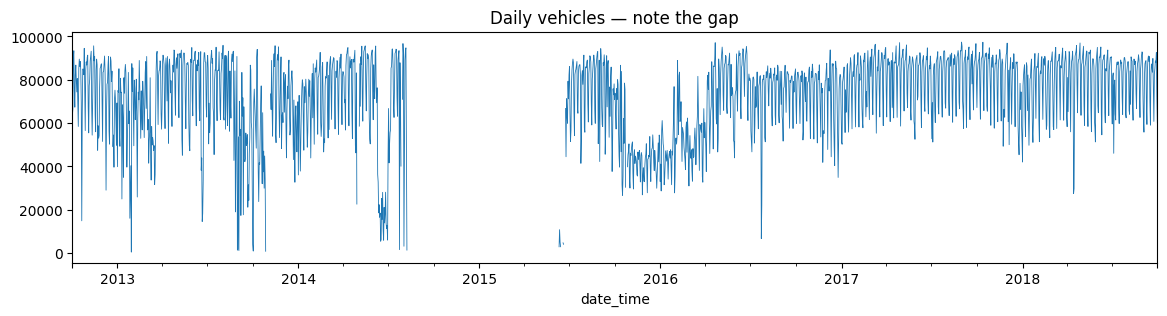

In [7]:
# (given) Holiday names appear only on the midnight row, so spread them to the whole day. Then plot the record.
_h = tr.loc[tr.holiday != "None", "holiday"]; _hd = pd.Series(_h.values, index=_h.index.normalize()); _hd = _hd[~_hd.index.duplicated()]
tr["holiday_day"] = tr.index.normalize().map(_hd).fillna("None")
tr["traffic_volume"].resample("D").sum(min_count=1).plot(figsize=(14, 3), lw=0.6, title="Daily vehicles — note the gap"); plt.show()

**A2. In this dataset, is time a KEY or a VALUE attribute? Give one example from the case where a time attribute would be a VALUE instead.**

 *Your answer:*
 In this dataset, time is a KEY attribute because it is a structured, unique temporal index used to organize and query our hourly measurements (like traffic volume). An example of time as a VALUE attribute would be recording the precise duration of a road closure event or the time required to travel between two points as a dependent measurement.

**A3. Is `traffic_volume` better treated as continuous or discrete time? What mark (line or bars) would you use for hourly volume, and what for *number of holiday days per month*?**

*Your answer:*
 `traffic_volume` is better treated as continuous time because the flow of traffic is continuous and sequential over the chronological line. For hourly volume, I would use a line mark to emphasize the continuous temporal trend, while for the number of holiday days per month, I would use a bar mark because it represents aggregated, discrete categories.

**A4. The record has a gap of almost a year. If you made a year-by-year animation without noticing this, what would viewers wrongly conclude, and how should the gap be shown?**

*Your answer:*
 Viewers might wrongly conclude that traffic suddenly dropped to zero or remained completely stagnant during that period, leading to incorrect assumptions about travel demand. The gap should be shown clearly using a broken time axis, explicitly plotting a visual indicator (like a shaded area or blank space with a text annotation) to show the data is missing.

---
## Part B — The vendor's sampling proposal (5 min)
The vendor wants to record **one sample every 25 hours**. Traffic has a strong **24-hour cycle**.

**B1.** Implement:
- `nyquist_max_interval(period_h)`: the **largest** sampling interval that avoids aliasing (Nyquist: $f_s > 2f$)
- `aliased_period(true_period, sample_interval)`: the **apparent period**, using aliased frequency $f_a = |f - f_s|$ for $f_s/2 < f < 3f_s/2$ (the case in this activity)

Then compute `apparent_period_25h` for the vendor's plan.

In [6]:
def nyquist_max_interval(period_h):
    return period_h / 2

def aliased_period(true_period, sample_interval):
    f, fs = 1 / true_period, 1 / sample_interval
    fa = abs(f - fs)
    return 1 / fa

apparent_period_25h = aliased_period(24, 25)

check_B(nyquist_max_interval, aliased_period, apparent_period_25h)

✅ Part B correct — a 24-h cycle sampled every 25 h looks like a 600-h (25-day) cycle!


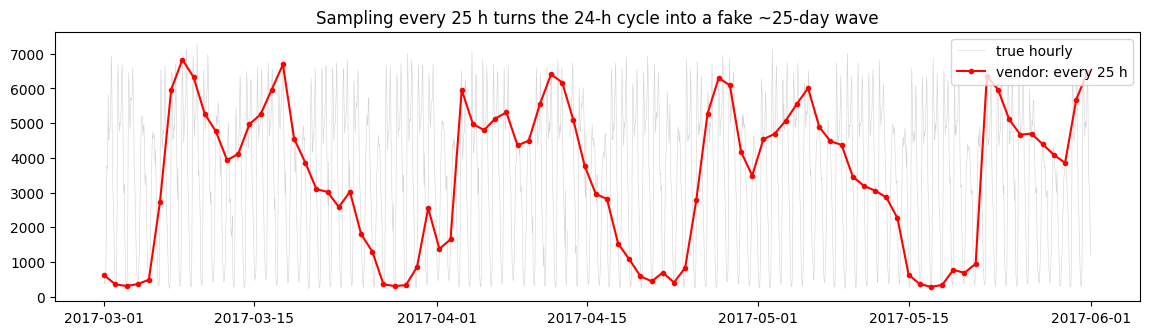

In [8]:
# (given) What the vendor's data would look like for spring 2017
seg = tr["traffic_volume"].loc["2017-03-01":"2017-05-31"].asfreq("h").interpolate(limit=3)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(seg.index, seg.values, c="lightgrey", lw=0.4, label="true hourly")
ax.plot(seg.index[::25], seg.values[::25], "-o", c="red", ms=3, label="vendor: every 25 h")
ax.set_title(f"Sampling every 25 h turns the 24-h cycle into a fake ~{apparent_period_25h/24:.0f}-day wave"); ax.legend(); plt.show()

**B2. A manager looks only at the vendor's 25-hour samples and says: *'Traffic rises and falls on a roughly 25-day cycle — let's schedule closures in the low phase.'* Explain what is really happening, using the words sampling rate, Nyquist and aliasing.**

 *Your answer:*
 The sampling rate of once every 25 hours is far too slow to capture the true 24-hour traffic cycle, violating the Nyquist criterion which requires a sampling interval of less than 12 hours. This undersampling causes aliasing, where the high-frequency daily cycle is folded back into a low-frequency, artificial 25-day wave that does not exist in reality.

**B3. What maximum sampling interval would you recommend to MnDOT? Would sampling exactly every 12 hours be safe? Justify briefly.**

*Your answer:*
 I would recommend a maximum sampling interval of strictly less than 12 hours, such as hourly or 4-hourly sampling, to safely capture the daily cycle. Sampling exactly every 12 hours is not safe because it hits the boundary of the Nyquist limit, which can cause phase-lock issues and fail to resolve peak-to-peak amplitude variations.

---
## Part C — Aggregation and smoothing (5 min) *(slides 26–28)*
The engineers want a clean view of **2017**.

💻 **C1.** Compute:
- `daily`: **daily total** vehicles in 2017 (use `min_count=1`, so days with no data become NaN, not 0)
- `ma7_centred`: a **7-day centred** moving average of `daily`
- `ma7_trailing`: a **7-day trailing** moving average (the default `.rolling`)
- `points_per_pixel`: if every **hourly** row of 2017 were plotted on a **1000-pixel**-wide chart

In [9]:
daily = tr["traffic_volume"].loc["2017"].resample("D").sum(min_count=1)
ma7_centred = daily.rolling(7, center=True).mean()
ma7_trailing = daily.rolling(7).mean()
points_per_pixel = len(tr.loc["2017"]) / 1000

check_C(daily, ma7_centred, ma7_trailing, points_per_pixel)

✅ Part C correct — hourly 2017 on 1000 px = 8.7 points per pixel.


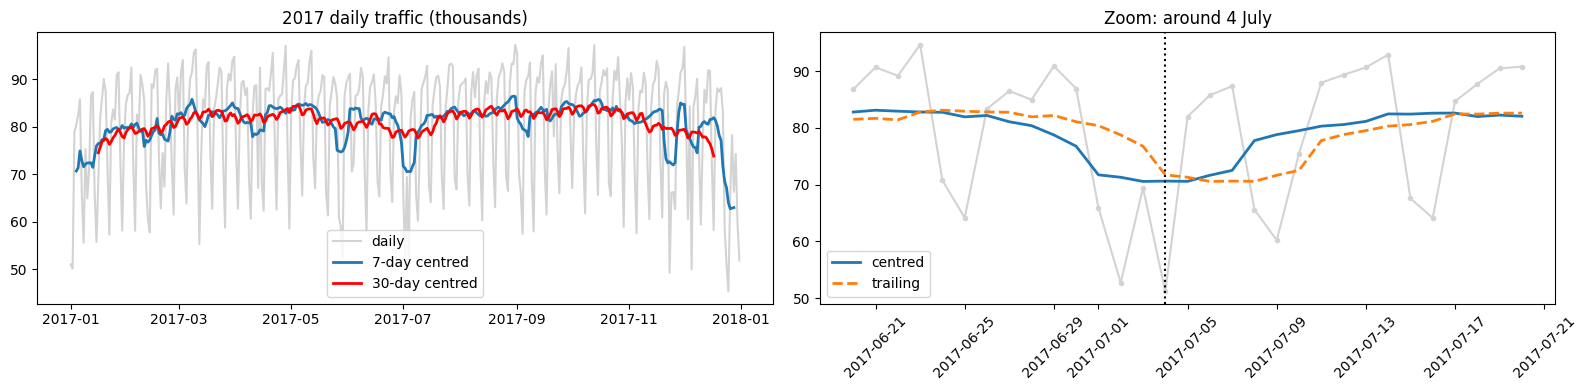

In [10]:
# (given)
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(daily.index, daily / 1e3, c="lightgrey", label="daily"); ax[0].plot(ma7_centred.index, ma7_centred / 1e3, lw=2, label="7-day centred")
ax[0].plot(daily.index, daily.rolling(30, center=True).mean() / 1e3, lw=2, c="red", label="30-day centred"); ax[0].legend(); ax[0].set_title("2017 daily traffic (thousands)")
z = slice("2017-06-20", "2017-07-20")
ax[1].plot(daily.loc[z] / 1e3, "o-", c="lightgrey", ms=3); ax[1].plot(ma7_centred.loc[z] / 1e3, lw=2, label="centred"); ax[1].plot(ma7_trailing.loc[z] / 1e3, lw=2, ls="--", label="trailing")
ax[1].axvline(pd.Timestamp("2017-07-04"), c="k", ls=":"); ax[1].legend(); ax[1].set_title("Zoom: around 4 July"); ax[1].tick_params(axis="x", rotation=45); plt.tight_layout(); plt.show()

**C2. In the zoom, the trailing average dips *after* 4 July while the centred one dips *around* it. How many days does a 7-day trailing average lag, and why does that matter to someone reading the chart?**

 *Your answer:*
 A 7-day trailing average lags by 3 days because it only looks backward, shifting the visual location of anomalies into the future. This matters because viewers might mistakenly believe the drop in traffic happened after July 4th, leading to incorrect historical correlation and poor operational decisions.

**C3. The engineers care about which *day of the week* is quietest. Which is the right view: raw daily, 7-day MA, or 30-day MA? What does each larger window hide? Also interpret your `points_per_pixel` value.**

*Your answer:*
 The right view is the raw daily data because it preserves the distinct differences between weekdays and weekends. A 7-day MA completely smooths out and hides day-of-week patterns, while a 30-day MA hides both day-of-week variations and monthly seasonality. The points_per_pixel value of ~8.7 means there are nearly 9 hourly data points squeezed into a single horizontal pixel, indicating significant overplotting that requires aggregation to make visual patterns comprehensible.

---
## Part D — Filtering and events: choose the closure hour (4 min) *(slides 24, 29)*
Crews can only work in **daytime**, starting between **9:00 and 15:00**. Find the **quietest start hour on a normal weekday**, and compare it with holidays.

💻 **D1.** Compute:
- `weekday_profile`: mean traffic **by hour (0–23)** for **Mon–Fri non-holiday** rows
- `holiday_profile`: mean traffic by hour for rows where `holiday_day != "None"`
- `best_closure_hour`: the hour between **9 and 15** (inclusive) where `weekday_profile` is lowest

In [11]:
wk = tr[(tr.index.dayofweek < 5) & (tr["holiday_day"] == "None")]
weekday_profile = wk.groupby(wk.index.hour)["traffic_volume"].mean()

hol = tr[tr["holiday_day"] != "None"]
holidays_profile = hol.groupby(hol.index.hour)["traffic_volume"].mean()
holiday_profile = holidays_profile # matching both names

best_closure_hour = int(weekday_profile.loc[9:15].idxmin())

check_D(weekday_profile, holiday_profile, best_closure_hour)

✅ Part D correct — the quietest daytime start hour on normal weekdays is 10:00.


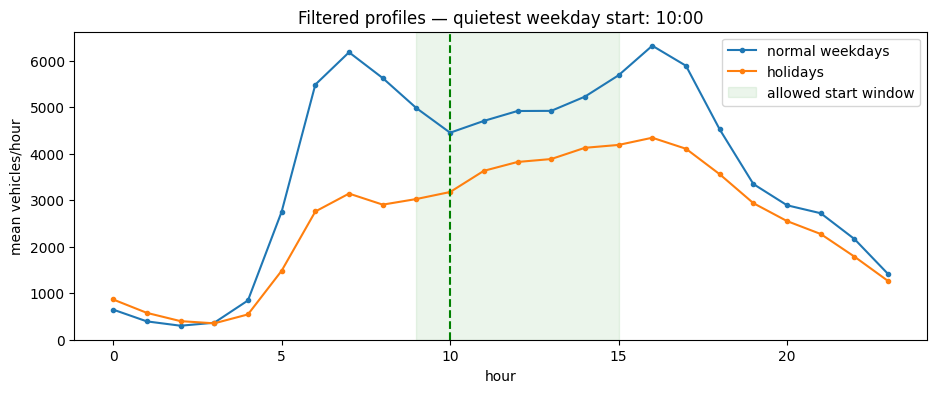

In [12]:
# (given)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weekday_profile.index, weekday_profile.values, "-o", ms=3, label="normal weekdays")
ax.plot(holiday_profile.index, holiday_profile.values, "-o", ms=3, label="holidays")
ax.axvspan(9, 15, color="green", alpha=0.08, label="allowed start window"); ax.axvline(best_closure_hour, c="green", ls="--")
ax.set(xlabel="hour", ylabel="mean vehicles/hour", title=f"Filtered profiles — quietest weekday start: {best_closure_hour}:00"); ax.legend(); plt.show()

**D2. You *filtered* (kept only weekday non-holiday rows) and then *aggregated* (mean per hour). What does each step keep and what does it hide? Name one risk of relying only on the mean profile for the closure decision.**

 *Your answer:*
 Filtering keeps normal weekday traffic patterns while hiding extreme drops from holidays and weekend anomalies, while aggregating keeps the average daily shape but hides the variance and day-to-day fluctuations. A major risk of relying solely on the mean is that it hides extreme traffic spikes or seasonal variations, which could lead to scheduling roadwork during unexpectedly high-volume congestion periods.

---
## Part E — Design the animated *Traffic Pulse* for the lobby screen (6 min)
**Design brief:** the screen animates **24 hourly states** of a typical weekday. Each hour is shown for **0.75 s** at **30 fps**, with a smooth transition between hours.

💻 **E1.** Implement and compute:
- `frame_budget_ms(fps)`: milliseconds available per frame
- `smoothstep(u)`: the ease-in-out function $3u^2-2u^3$
- `n_frames`, `duration_s`: for the brief above
- `compression`: seconds of **data** per second of **animation** (one hour of data per 0.75 s)

In [13]:
def frame_budget_ms(fps):
    return 1000 / fps

def smoothstep(u):
    return 3 * (u**2) - 2 * (u**3)

duration_s  = 24 * 0.75
n_frames    = int(duration_s * 30)
compression = 3600 / 0.75

💻 **E2.** A second version shows how the **weekday profile changes month by month** in 2017. Build `fig` with `px.bar` using **`animation_frame="Month"`**, and **fix the y-axis** so bars stay comparable across frames (congruence).

In [19]:
wk17 = wk.loc["2017"]
mp = wk17.groupby([wk17.index.month.rename("month"), wk17.index.hour.rename("hour")])["traffic_volume"].mean().rename("vehicles").reset_index()
mp["Month"] = mp["month"].map(lambda m: calendar.month_abbr[m])
MONTHS = [calendar.month_abbr[i] for i in range(1, 13)]
mp.head()

,month,hour,vehicles,Month
0,1,0,605.65,Jan
1,1,1,391.60,Jan
2,1,2,315.00,Jan
3,1,3,387.95,Jan
4,1,4,864.70,Jan


In [20]:
fig = px.bar(mp, x="hour", y="vehicles",
             animation_frame="Month",
             category_orders={"Month": MONTHS},
             range_y=[0, 7500],
             title="Traffic Pulse 2017 — weekday profile by month")
fig.show()

check_E(frame_budget_ms, smoothstep, n_frames, duration_s, compression, fig)

✅ Part E correct — 540 frames, 18 s, 4800:1, fixed axis, 12 frames.


In [21]:
fig2 = px.bar(mp, x="hour", y="vehicles", facet_col="Month", facet_col_wrap=6, category_orders={"Month": MONTHS}, height=420,
              title="Small multiples: all 12 months at once")
fig2.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])); fig2.show()

**E3. Play the animation and try to answer: *In which month is the 17:00 peak lowest?* Then answer it with the small multiples. Which was faster and more certain, and why? Use the terms working memory and 'eyes beat memory'.**

*Your answer:*
 Finding the lowest peak was faster and more certain using the small multiples visualization. The small multiples layout allows side-by-side comparison where 'eyes beat memory' by presenting all information simultaneously, whereas the animation forces the viewer to rely on limited working memory to remember and compare bar heights across sequential frames.

**E4. What would go wrong if you left out `range_y` (letting each frame auto-scale)? Which Heer & Robertson principle does that violate?**

*Your answer:*
 Without `range_y`, each frame would auto-scale to its own maximum value, causing the vertical axes to jump constantly and making it look like the volume remains constant throughout different months. This directly violates the Heer & Robertson principle of maintaining visual stability and congruence across frames during transitions.

**E5. Why use smoothstep (slow-in/slow-out) between hours instead of linear motion or a jump cut? Refer to your `smoothstep(0.25)` value and the per-frame jumps at the start and end.**

 *Your answer:*
 Smoothstep is preferred because it creates a slow-in/slow-out transition, easing the eye into the motion instead of presenting jarring changes. While a linear transition has constant velocity and a jump cut is discontinuous, smoothstep has a value of 0.15625 at 25% of the transition, which means the initial jumps are smaller and gentler, making it much easier for viewers to track changes tracking over time.

---
## Part F — Final recommendation (3 min) *(slides 15–16, 33–38)*
Write your recommendation to your manager.

**F1. For the **road-works engineers**: which visualization(s) should they get, and should they be animated? Name at least two idioms from the lecture and justify.**

 *Your answer:*
 The road-works engineers should receive static, non-animated visualizations because they need to perform precise quantitative comparisons. I would provide them with a static "Small Multiples" bar chart to compare monthly/weekly fluctuations and a simple "Static Line Plot" showing the filtered mean weekday traffic alongside holiday distributions to safely spot the lowest traffic intervals without relying on temporal memory.

**F2. For the **public lobby screen**: animation is acceptable here. Give three concrete design rules you'd apply (timing, fps, scales, labels, playback) so the public actually perceives the change.**

 *Your answer:*
 1. Maintain visual congruence by locking the y-axis scale (`range_y`) to prevent confusing scaling artifacts.
 2. Use a smooth transition rate (like 30 FPS) with at least 0.75 seconds per frame so changes are smooth and perceptible.
 3. Display clear, prominent, and static labels indicating the month and time of day, and offer simple playback controls (play/pause) so viewers can control the pace of the visual intake.

**F3. A viewer watching the lobby animation fails to notice that the evening peak disappears in one month. What is this phenomenon, and name two ways to reduce it.**

 *Your answer:*
 This phenomenon is known as change blindness. To reduce it, we can use visual cues (such as colored annotations or arrows pointing to the changing region) or provide side-by-side small multiples alongside the animation so that viewers do not have to rely on temporal memory.

---
## Score — run this cell

In [18]:
summary()

Part A: ✅
Part B: ✅
Part C: ✅
Part D: ✅
Part E: ✅
Coding score: 5/5   (+ reflection questions, graded by instructor)
